In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("Data_Tanaman_Padi_Sumatera_version_1.csv")

print(f"Dataset : {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Kolom: {list(df.columns)}")
print(f"Data kosong: {df.isnull().sum().sum()}")

# Lihat 5 baris pertama
print("5 Baris Pertama:")
print(df.head())

print("Tipe Data:")
print(df.dtypes)

Dataset : 224 baris, 7 kolom
Kolom: ['Provinsi', 'Tahun', 'Produksi', 'Luas Panen', 'Curah hujan', 'Kelembapan', 'Suhu rata-rata']
Data kosong: 0
5 Baris Pertama:
  Provinsi  Tahun   Produksi  Luas Panen  Curah hujan  Kelembapan  \
0     Aceh   1993  1329536.0    323589.0       1627.0       82.00   
1     Aceh   1994  1299699.0    329041.0       1521.0       82.12   
2     Aceh   1995  1382905.0    339253.0       1476.0       82.72   
3     Aceh   1996  1419128.0    348223.0       1557.0       83.00   
4     Aceh   1997  1368074.0    337561.0       1339.0       82.46   

   Suhu rata-rata  
0           26.06  
1           26.92  
2           26.27  
3           26.08  
4           26.31  
Tipe Data:
Provinsi           object
Tahun               int64
Produksi          float64
Luas Panen        float64
Curah hujan       float64
Kelembapan        float64
Suhu rata-rata    float64
dtype: object


In [3]:
print("Membersihkan data")

# Hapus duplikat
before = df.shape[0]
df = df.drop_duplicates()
after = df.shape[0]
print(f"Dihapus {before - after} data duplikat")

# Tangani missing values jika ada
if df.isnull().sum().sum() > 0:
    print("⚠️ Menangani missing values...")
    # Untuk kolom numerik, isi dengan median
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if df[col].isnull().sum() > 0:
            df[col].fillna(df[col].median(), inplace=True)
    
    # Untuk kolom kategorikal, isi dengan modus
    categorical_cols = df.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        if df[col].isnull().sum() > 0:
            df[col].fillna(df[col].mode()[0], inplace=True)
    
    print(f"Missing values telah ditangani")

# Cek statistik dasar
print("Statistik Dasar:")
print(df.describe())

Membersihkan data
Dihapus 0 data duplikat
Statistik Dasar:
             Tahun      Produksi     Luas Panen  Curah hujan  Kelembapan  \
count   224.000000  2.240000e+02     224.000000   224.000000  224.000000   
mean   2006.500000  1.679701e+06  374349.966920  2452.490759   80.948705   
std       8.095838  1.161387e+06  232751.161987  1031.972625    4.878680   
min    1993.000000  4.293800e+04   63142.040000   222.500000   54.200000   
25%    1999.750000  5.488570e+05  146919.500000  1703.525000   78.975000   
50%    2006.500000  1.667773e+06  373551.500000  2315.700000   82.375000   
75%    2013.250000  2.436851e+06  514570.250000  3039.700000   84.000000   
max    2020.000000  4.881089e+06  872737.000000  5522.000000   90.600000   

       Suhu rata-rata  
count      224.000000  
mean        26.801964  
std          1.197041  
min         22.190000  
25%         26.177500  
50%         26.730000  
75%         27.200000  
max         29.850000  


Visualisasi produksi


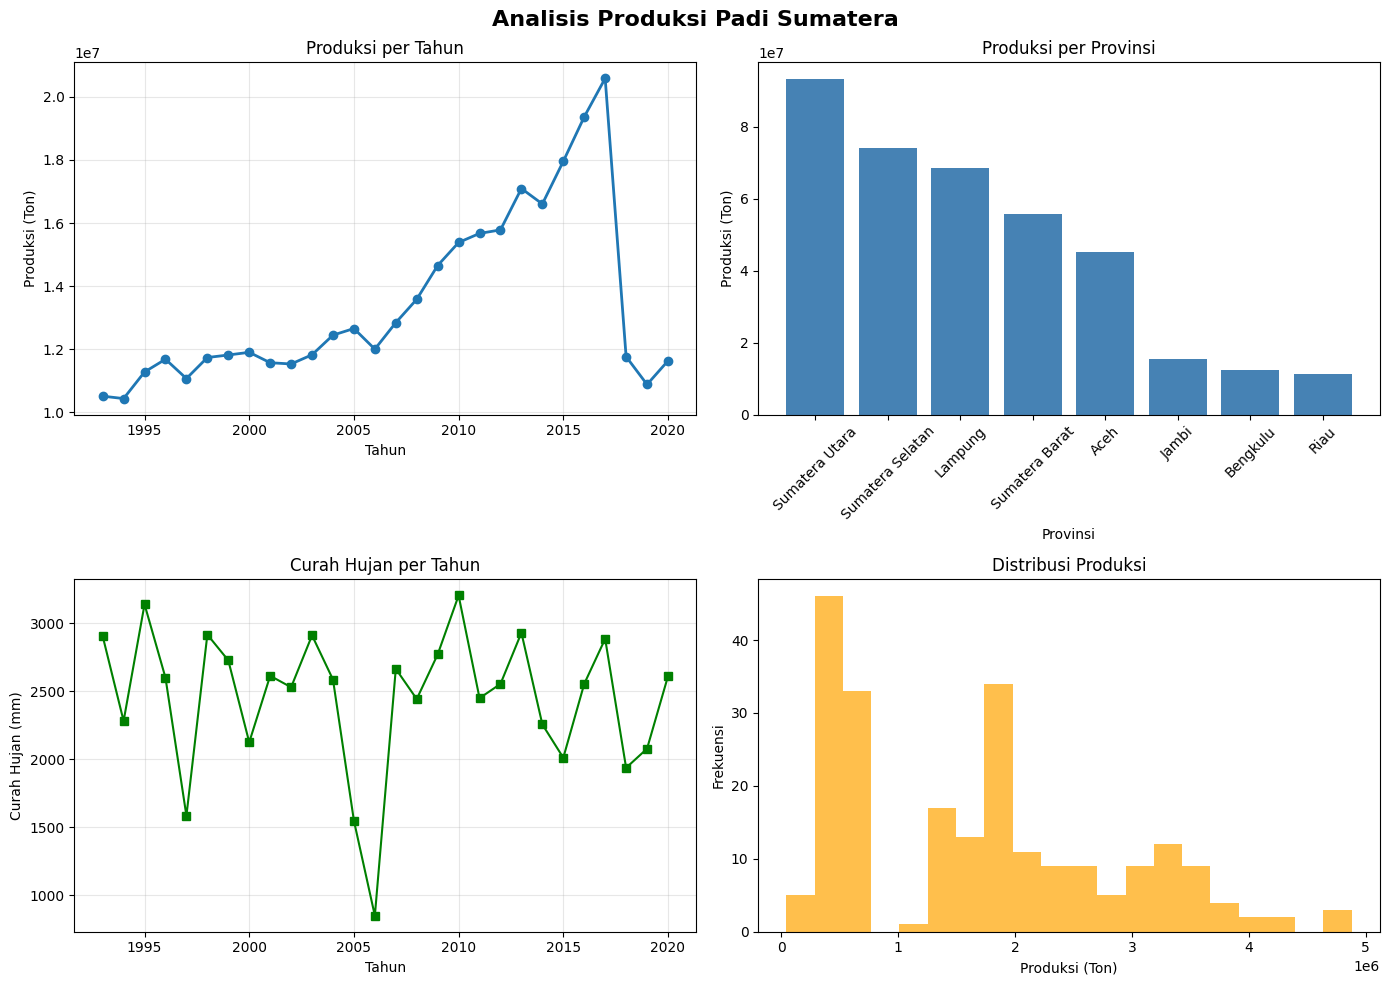

Ringkasan Produksi:
Total produksi: 376,252,999 ton
Rata-rata produksi: 1,679,701 ton
Produksi tertinggi: 4,881,089 ton


In [4]:
print("Visualisasi produksi")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Analisis Produksi Padi Sumatera', fontsize=16, fontweight='bold')

# Produksi per tahun
yearly = df.groupby('Tahun')['Produksi'].sum()
axes[0,0].plot(yearly.index, yearly.values, marker='o', linewidth=2)
axes[0,0].set_title('Produksi per Tahun')
axes[0,0].set_xlabel('Tahun')
axes[0,0].set_ylabel('Produksi (Ton)')
axes[0,0].grid(True, alpha=0.3)

# Produksi per provinsi
province = df.groupby('Provinsi')['Produksi'].sum().sort_values(ascending=False)
axes[0,1].bar(range(len(province)), province.values, color='steelblue')
axes[0,1].set_title('Produksi per Provinsi')
axes[0,1].set_xlabel('Provinsi')
axes[0,1].set_ylabel('Produksi (Ton)')
axes[0,1].set_xticks(range(len(province)))
axes[0,1].set_xticklabels(province.index, rotation=45)

# Curah hujan per tahun
rainfall = df.groupby('Tahun')['Curah hujan'].mean()
axes[1,0].plot(rainfall.index, rainfall.values, marker='s', color='green')
axes[1,0].set_title('Curah Hujan per Tahun')
axes[1,0].set_xlabel('Tahun')
axes[1,0].set_ylabel('Curah Hujan (mm)')
axes[1,0].grid(True, alpha=0.3)

# Distribusi produksi
axes[1,1].hist(df['Produksi'], bins=20, alpha=0.7, color='orange')
axes[1,1].set_title('Distribusi Produksi')
axes[1,1].set_xlabel('Produksi (Ton)')
axes[1,1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

print("Ringkasan Produksi:")
print(f"Total produksi: {df['Produksi'].sum():,.0f} ton")
print(f"Rata-rata produksi: {df['Produksi'].mean():,.0f} ton")
print(f"Produksi tertinggi: {df['Produksi'].max():,.0f} ton")

In [5]:
print("\n🔄 Mengkonversi data kategorikal...")

# Buat salinan dataframe untuk modeling
df_model = df.copy()

# Encode kolom Provinsi
le_provinsi = LabelEncoder()
df_model['Provinsi_encoded'] = le_provinsi.fit_transform(df_model['Provinsi'])

print(f"✅ Provinsi di-encode: {list(le_provinsi.classes_)}")

# Hapus kolom asli Provinsi dan Tahun untuk modeling
df_model = df_model.drop(columns=['Provinsi', 'Tahun'])

print(f"📊 Kolom untuk modeling: {list(df_model.columns)}")


🔄 Mengkonversi data kategorikal...
✅ Provinsi di-encode: ['Aceh', 'Bengkulu', 'Jambi', 'Lampung', 'Riau', 'Sumatera Barat', 'Sumatera Selatan', 'Sumatera Utara']
📊 Kolom untuk modeling: ['Produksi', 'Luas Panen', 'Curah hujan', 'Kelembapan', 'Suhu rata-rata', 'Provinsi_encoded']


Analisis korelasi


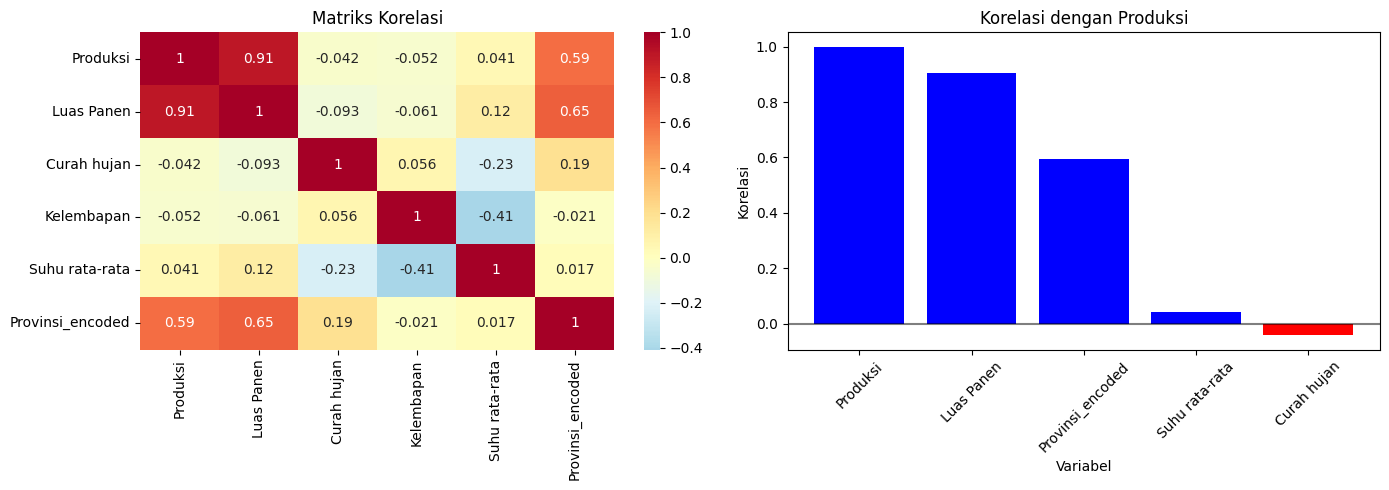

🔗 Korelasi dengan Produksi:
Luas Panen: 0.906
Provinsi_encoded: 0.595
Suhu rata-rata: 0.041
Curah hujan: -0.042
Kelembapan: -0.052


In [6]:
print("Analisis korelasi")

# Hitung korelasi dengan produksi
correlations = df_model.corr()['Produksi'].sort_values(ascending=False)

# Visualisasi korelasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap korelasi
sns.heatmap(df_model.corr(), annot=True, cmap='RdYlBu_r', 
            center=0, ax=axes[0])
axes[0].set_title('Matriks Korelasi')

# Bar plot korelasi dengan produksi
corr_with_prod = correlations[:-1]  # Hilangkan korelasi dengan diri sendiri
colors = ['red' if x < 0 else 'blue' for x in corr_with_prod]
axes[1].bar(range(len(corr_with_prod)), corr_with_prod.values, color=colors)
axes[1].set_title('Korelasi dengan Produksi')
axes[1].set_xlabel('Variabel')
axes[1].set_ylabel('Korelasi')
axes[1].set_xticks(range(len(corr_with_prod)))
axes[1].set_xticklabels(corr_with_prod.index, rotation=45)
axes[1].axhline(y=0, color='black', linestyle='-', alpha=0.5)

plt.tight_layout()
plt.show()

print("🔗 Korelasi dengan Produksi:")
for var, corr in correlations.items():
    if var != 'Produksi':
        print(f"{var}: {corr:.3f}")

In [7]:

#Mempersiapkan data untuk model

# Pisahkan fitur dan target
X = df_model.drop('Produksi', axis=1)
y = df_model['Produksi']

print(f"Fitur yang digunakan: {list(X.columns)}")

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Fitur telah di-standardisasi")



Fitur yang digunakan: ['Luas Panen', 'Curah hujan', 'Kelembapan', 'Suhu rata-rata', 'Provinsi_encoded']
Fitur telah di-standardisasi


In [8]:
# Membuat model prediksi

# Bagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(f"Data training: {X_train.shape[0]} samples")
print(f"Data testing: {X_test.shape[0]} samples")

# Training model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediksi
y_pred = model.predict(X_test)

# Evaluasi model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Akurasi: {r2*100:.1f}%")

Data training: 179 samples
Data testing: 45 samples

Mean Squared Error: 117877722847.4830
R² Score: 0.8667
Akurasi: 86.7%


Visualisasi hasil prediksi


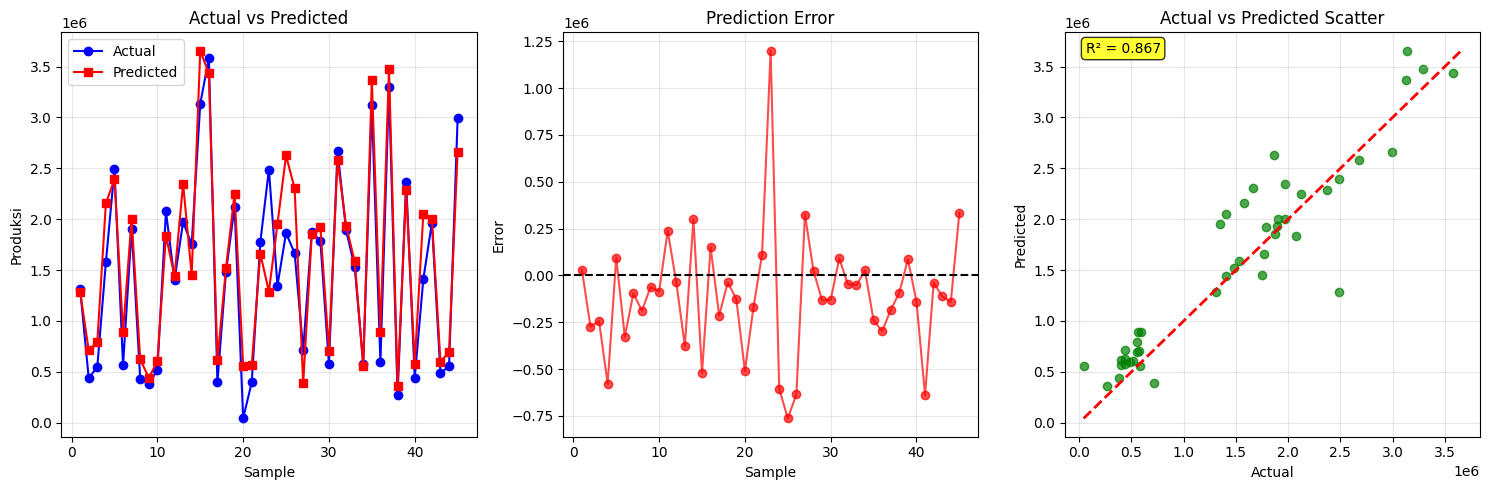

Luas Panen: 1047152.892
Suhu rata-rata: 70018.497
Provinsi_encoded: 24305.486
Kelembapan: 18439.328
Curah hujan: 17917.077
Mapping Provinsi:
Aceh: 0
Bengkulu: 1
Jambi: 2
Lampung: 3
Riau: 4
Sumatera Barat: 5
Sumatera Selatan: 6
Sumatera Utara: 7
Analisis selesai!
Model dapat memprediksi produksi padi dengan akurasi 86.7%


In [9]:
print("Visualisasi hasil prediksi")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Actual vs Predicted
indices = range(1, len(y_test) + 1)
axes[0].plot(indices, y_test, 'b-', label='Actual', marker='o')
axes[0].plot(indices, y_pred, 'r-', label='Predicted', marker='s')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Sample')
axes[0].set_ylabel('Produksi')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Error plot
error = y_test - y_pred
axes[1].plot(indices, error, 'ro-', alpha=0.7)
axes[1].axhline(y=0, color='black', linestyle='--')
axes[1].set_title('Prediction Error')
axes[1].set_xlabel('Sample')
axes[1].set_ylabel('Error')
axes[1].grid(True, alpha=0.3)

# 3. Scatter plot
axes[2].scatter(y_test, y_pred, alpha=0.7, color='green')
min_val, max_val = min(min(y_test), min(y_pred)), max(max(y_test), max(y_pred))
axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
axes[2].set_xlabel('Actual')
axes[2].set_ylabel('Predicted')
axes[2].set_title('Actual vs Predicted Scatter')
axes[2].text(0.05, 0.95, f'R² = {r2:.3f}', transform=axes[2].transAxes, 
             bbox=dict(boxstyle="round", facecolor='yellow', alpha=0.8))
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Feature importance
feature_names = X.columns
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': np.abs(model.coef_)
}).sort_values('Importance', ascending=False)

for i, row in importance.iterrows():
    print(f"{row['Feature']}: {row['Importance']:.3f}")

# Mapping provinsi untuk interpretasi
print("Mapping Provinsi:")
for i, prov in enumerate(le_provinsi.classes_):
    print(f"{prov}: {i}")

print("Analisis selesai!")
print(f"Model dapat memprediksi produksi padi dengan akurasi {r2*100:.1f}%")